# Is a Social Circle Also a Music Circle?
## Community Detection in the LastFM Asia Social Network

**STAT 236, Fall 2026** · Faye Fang, Grace Chen

**Question.** We detect communities using **only** the mutual-follow network, and then use users' liked artists, which are never used for detection or tuning, to test whether users in the same community share music taste more than users in different communities.

**How this notebook is organized**

| § | Content | Use in report |
|---|---|---|
| 0 | Setup and configuration | Reproducibility |
| 1 | Data and preprocessing | Main text: Data |
| 2 | Community detection: Spectral, SCORE, SCORE+, Louvain; choosing τ, K, γ | Main text: Methodology |
| 3 | Music similarity (Jaccard) | Main text: Methodology |
| 4 | Main test: stratified permutation test of T | Main text: Results (headline) |
| 5 | Country as a confounder | Main text: Robustness |
| 6 | Method comparison (NMI, hub placement) | Main text: Results |
| 7 | Robustness (K, γ, τ, popular artists, alternative T) | Main text (short) + Appendix |
| 8 | Network visualizations | Webpage / figures |
| A | Appendix: DCBM simulation | Appendix |
| 9 | Summary, implementation choices, takeaways | Report and talk |

All figures are saved to `figures/` and all tables to `tables/` so they can be reused in the report and webpage directly. Lecture references (e.g. *Lec9 slide 37*) point to the course slides, Chapter 3.

## 0. Setup

In [1]:
import os, json, time, random, warnings, platform
import numpy as np
import pandas as pd
import networkx as nx
import scipy
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score as NMI, adjusted_rand_score as ARI
import matplotlib as mpl
import matplotlib.pyplot as plt
import igraph as ig

warnings.filterwarnings('ignore', category=RuntimeWarning)

# ---- configuration -------------------------------------------------------
SEED = 236                 # global seed; every random step derives from it
DATA_DIR, FIG_DIR, TAB_DIR, OUT_DIR = 'data', 'figures', 'tables', 'outputs'
for d in (FIG_DIR, TAB_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

B_MAIN   = 1000   # permutations for the main tests (proposal: 1,000)
B_ROBUST = 200    # permutations for robustness checks
N_SUB    = 10     # edge-subsamples for K-selection stability
N_SIM    = 20     # replications per DCBM simulation setting
N_INIT   = 20     # k-means random starts
K_RANGE  = range(3, 21)

# ---- plotting style (consistent colors per method across all figures) ----
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
METHOD_ORDER = ['Spectral', 'SCORE', 'SCORE+', 'Louvain']
METHOD_COLOR = {'SCORE+': '#2a78d6', 'Louvain': '#eb6834', 'SCORE': '#1baf7a', 'Spectral': '#eda100'}
CAT8 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
OTHER = '#b9b8b2'
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False, 'lines.linewidth': 2,
})
def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'))
def savetab(df, name, index=False):
    df.to_csv(os.path.join(TAB_DIR, name + '.csv'), index=index)

print('Python', platform.python_version(), '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| scikit-learn', sklearn.__version__, '| igraph', ig.__version__)

Python 3.13.16 | numpy 2.5.3 | scipy 1.18.1 | networkx 3.7 | scikit-learn 1.9.1 | igraph 1.0.0


## 1. Data and preprocessing

**Source.** LastFM Asia Social Network (Rozemberczki & Sarkar, 2020), SNAP: https://snap.stanford.edu/data/feather-lastfm-social.html. Users are nodes, mutual follows are undirected edges, and each user has a list of liked artists (anonymous integer IDs). The file also contains each user's **country** (anonymous code, 18 classes); we use it only in §5 as a potential confounder.

The loader accepts either the original SNAP files (`lastfm_asia_edges.csv`, `lastfm_asia_features.json`, `lastfm_asia_target.csv`) or the identical dataset as distributed in the authors' `karateclub` repository (`lastfm_edges.csv`, `lastfm_features.csv`, `lastfm_target.csv`). Put the files in `data/`.

**Preprocessing (as in the proposal).** Check duplicate edges and self-loops; keep users who have music data; keep the largest connected component (LCC) of the network induced on them. The LCC is required by SCORE-type methods, whose leading eigenvector must be strictly positive.

In [2]:
def load_lastfm(data_dir=DATA_DIR):
    p = lambda f: os.path.join(data_dir, f)
    if os.path.exists(p('lastfm_asia_edges.csv')):                     # SNAP version
        edges = pd.read_csv(p('lastfm_asia_edges.csv'))
        target = pd.read_csv(p('lastfm_asia_target.csv'))
        with open(p('lastfm_asia_features.json')) as fh:
            feats = json.load(fh)
        rows = [(int(u), a) for u, arts in feats.items() for a in arts]
        likes = pd.DataFrame(rows, columns=['node_id', 'artist_id'])
        src = 'SNAP'
    else:                                                               # karateclub version
        edges = pd.read_csv(p('lastfm_edges.csv'))
        target = pd.read_csv(p('lastfm_target.csv'))
        fpath = p('lastfm_features.csv') if os.path.exists(p('lastfm_features.csv')) else p('lastfm_features.csv.gz')
        likes = pd.read_csv(fpath).rename(columns={'feature_id': 'artist_id'})[['node_id', 'artist_id']]
        src = 'karateclub'
    edges.columns = ['u', 'v']
    target.columns = ['node_id', 'country']
    return edges, likes, target, src

edges_raw, likes_raw, target, SRC = load_lastfm()
print(f'source: {SRC} | edge rows: {len(edges_raw):,} | like rows: {len(likes_raw):,} | users with country: {len(target):,}')

source: karateclub | edge rows: 27,806 | like rows: 3,014,361 | users with country: 7,624


In [3]:
# --- integrity checks -----------------------------------------------------
n_self = int((edges_raw.u == edges_raw.v).sum())
canon = np.sort(edges_raw[['u', 'v']].values, axis=1)
n_dup = int(pd.DataFrame(canon).duplicated().sum())
n_dup_likes = int(likes_raw.duplicated().sum())

G_full = nx.Graph()
G_full.add_nodes_from(target.node_id)
G_full.add_edges_from(canon[canon[:, 0] != canon[:, 1]])
music_users = set(likes_raw.node_id.unique())

G_music = G_full.subgraph([v for v in G_full if v in music_users])
lcc = max(nx.connected_components(G_music), key=len)
G = G_music.subgraph(lcc).copy()

nodes = np.array(sorted(G.nodes()))
n = len(nodes)
idx = {v: i for i, v in enumerate(nodes)}
A = nx.to_scipy_sparse_array(G, nodelist=nodes, format='csr').astype(np.float64)
deg = np.asarray(A.sum(1)).ravel()
country = target.set_index('node_id').loc[nodes, 'country'].values

# user x artist incidence matrix
lk = likes_raw.drop_duplicates()
lk = lk[lk.node_id.isin(idx)]
X = sp.csr_matrix((np.ones(len(lk), dtype=np.float32), (lk.node_id.map(idx).values, lk.artist_id.values)),
                  shape=(n, int(likes_raw.artist_id.max()) + 1))
X = X[:, np.asarray(X.sum(0)).ravel() > 0].tocsr()      # drop artists nobody in the sample likes
n_art = np.asarray(X.sum(1)).ravel()
art_pop = np.asarray(X.sum(0)).ravel()

summary = pd.DataFrame([
    ('Users (raw)', G_full.number_of_nodes()),
    ('Mutual-follow edges (raw)', len(edges_raw)),
    ('Self-loops', n_self),
    ('Duplicate edges', n_dup),
    ('Connected components (raw graph)', nx.number_connected_components(G_full)),
    ('Users without music data', G_full.number_of_nodes() - len(music_users & set(G_full))),
    ('Components after dropping them', nx.number_connected_components(G_music)),
    ('Users in final sample (LCC)', n),
    ('Edges in final sample', G.number_of_edges()),
    ('Distinct artists in final sample', X.shape[1]),
    ('Mean degree', round(deg.mean(), 2)),
    ('Median degree', np.median(deg)),
    ('Max degree', int(deg.max())),
    ('Mean #artists per user', round(float(n_art.mean()), 1)),
    ('Median #artists per user', np.median(n_art)),
    ('Min #users per artist', int(art_pop.min())),
    ('Countries', len(np.unique(country))),
], columns=['Quantity', 'Value'])
summary['Value'] = [f'{v:,.0f}' if float(v).is_integer() else f'{v:,.1f}' for v in summary.Value.astype(float)]
savetab(summary, 'tab01_data_summary')
summary

,Quantity,Value
0,Users (raw),"7,624"
1,Mutual-follow edges (raw),"27,806"
2,Self-loops,0
3,Duplicate edges,0
4,Connected components (raw graph),1
5,Users without music data,173
6,Components after dropping them,18
7,Users in final sample (LCC),"7,431"
8,Edges in final sample,"27,045"
9,Distinct artists in final sample,"7,842"


> **Interpretation.** The raw network is clean: one connected component, no self-loops, no duplicate edges. 173 users (2.3%) have no liked-artist data. Dropping them breaks off 17 tiny fragments, so the analysis sample is the LCC with **n = 7,431 users and 27,045 edges** (97.5% of all users). The network is **very sparse** (mean degree 7.3, median 4) yet contains **hubs with up to 214 friends**. Each user likes about 400 of the 7,842 artists, and every artist is liked by roughly 100 or more users, i.e. the released artist list appears to be pre-filtered to reasonably popular artists. Artist IDs are anonymous, so communities can be described by size, country mix and taste similarity, but not by genre.

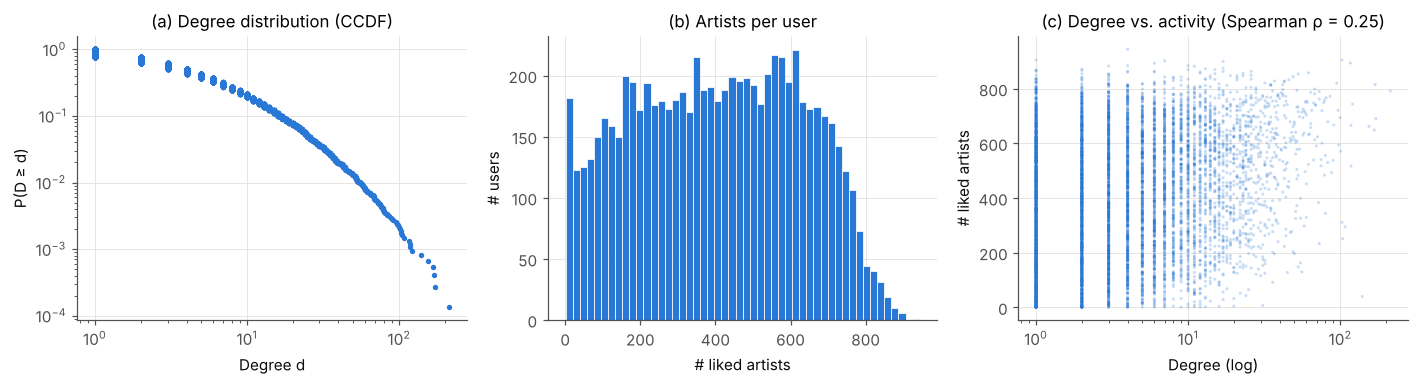

Spearman correlation between degree and #artists: 0.246
Degree quantiles (50/90/99/max): [ 4.  16.  54.7] 214


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) degree distribution (log-log CCDF)
ds = np.sort(deg)
ccdf = 1 - np.arange(n) / n
ax[0].loglog(ds, ccdf, color=METHOD_COLOR['SCORE+'], marker='o', ms=2.5, lw=0)
ax[0].set(xlabel='Degree d', ylabel='P(D ≥ d)', title='(a) Degree distribution (CCDF)')
# (b) number of artists per user
ax[1].hist(n_art, bins=50, color=METHOD_COLOR['SCORE+'], edgecolor='white', linewidth=0.5)
ax[1].set(xlabel='# liked artists', ylabel='# users', title='(b) Artists per user')
# (c) degree vs #artists
ax[2].scatter(deg, n_art, s=4, alpha=0.25, color=METHOD_COLOR['SCORE+'], edgecolor='none')
ax[2].set_xscale('log')
rho = pd.Series(deg).corr(pd.Series(n_art), method='spearman')
ax[2].set(xlabel='Degree (log)', ylabel='# liked artists', title=f'(c) Degree vs. activity (Spearman ρ = {rho:.2f})')
fig.tight_layout(); savefig(fig, 'fig01_degree_artists'); plt.show()
print(f'Spearman correlation between degree and #artists: {rho:.3f}')
print('Degree quantiles (50/90/99/max):', np.quantile(deg, [.5, .9, .99]).round(1), int(deg.max()))

> **Interpretation.** (a) The degree distribution is heavy-tailed: the CCDF is close to a straight line on log–log axes over two orders of magnitude, and the 99th percentile (≈55) is 14× the median (4). This is exactly the **degree heterogeneity** that the DCBM models with $\theta_i$ and that motivates SCORE-type methods. (b) The number of liked artists is broad (≈1 to 944) and roughly symmetric around 400. (c) Degree and activity are positively but weakly correlated (Spearman ρ = 0.25). Active users have more friends **and** more artists, which can inflate similarity among popular users. This is why the permutation test stratifies on both (§4).

## 2. Community detection

All methods see **only the adjacency matrix A**. Let $d_i$ be the degree of node $i$, $D=\mathrm{diag}(d_i)$, $\bar d$ the mean degree, and $K$ the number of communities. Eigenvectors are always ordered by the **absolute value** of their eigenvalues (Lec9).

| Method | Steps | Role |
|---|---|---|
| **Spectral clustering** (Lec9 slides 3–12) | top-$K$ eigenvectors $\hat\xi_1,\dots,\hat\xi_K$ of $A$ → k-means on the rows of $[\hat\xi_1,\dots,\hat\xi_K]$ | Baseline, no degree correction |
| **SCORE** (Jin 2015; Lec9 slides 17–21) | ratios $\hat R=[\hat\xi_2/\hat\xi_1,\dots,\hat\xi_K/\hat\xi_1]$ (entry-wise, truncated at $\pm\log n$) → k-means | Post-PCA degree correction |
| **SCORE+** (Jin, Ke & Luo 2021; Lec9 slides 35–43) | (i) regularized Laplacian $L_\tau=(D+\tau I)^{-1/2}A(D+\tau I)^{-1/2}$; (ii) top-$M$ eigenpairs, $M=K+1$ if $1-\hat\lambda_{K+1}/\hat\lambda_K < t$ else $K$; (iii) $\hat\eta_k=\hat\lambda_k\hat\xi_k$, $\hat R=[\hat\eta_2/\hat\eta_1,\dots,\hat\eta_M/\hat\eta_1]$; (iv) k-means with $K$ clusters | **Main method**: pre- *and* post-PCA degree correction |
| **Louvain** (Blondel et al. 2008) | greedy maximization of modularity $Q_\gamma=\frac{1}{2m}\sum_{ij}\big(A_{ij}-\gamma\frac{d_id_j}{2m}\big)\mathbf 1\{c_i=c_j\}$: move single nodes to the neighboring community with the largest gain in $Q_\gamma$, then collapse communities into super-nodes and repeat | External benchmark (not covered in lecture; same family as CMM in Lec9 slide 44); chooses $K$ itself, resolution $\gamma$ controls granularity |

Why degree correction matters: under the DCBM (Lec8), $\mathbb E[A_{ij}]=\theta_i\theta_j B_{c_ic_j}$, so each population eigenvector equals $\theta\circ$ (a community-wise constant vector). Spectral clustering on $A$ therefore clusters partly by $\theta_i$ (popularity). SCORE cancels $\theta_i$ by taking ratios. SCORE+ additionally down-weights extreme degrees *before* PCA.

**Implementation.** Spectral, SCORE and SCORE+ are implemented below from scratch (`scipy.sparse.linalg.eigsh` + `sklearn` k-means with 20 random starts). Louvain uses `networkx.community.louvain_communities` with package defaults except `resolution` and `seed`. Communities are relabelled by size (0 = largest).

In [5]:
def leading_eigs(M, k):
    """Top-k eigenpairs of a symmetric sparse matrix, ordered by |eigenvalue|; xi_1 made positive."""
    vals, vecs = eigsh(M, k=k, which='LM')
    o = np.argsort(-np.abs(vals))
    vals, vecs = vals[o], vecs[:, o]
    if vecs[:, 0].sum() < 0:
        vecs[:, 0] *= -1
    return vals, vecs

def reg_laplacian(A, tau):
    d = np.asarray(A.sum(1)).ravel()
    Dm = sp.diags(1.0 / np.sqrt(d + tau))
    return (Dm @ A @ Dm).tocsr()

def relabel_by_size(lab):
    """Relabel so that community 0 is the largest."""
    _, inv, cnt = np.unique(lab, return_inverse=True, return_counts=True)
    rank = np.empty_like(cnt); rank[np.argsort(-cnt, kind='stable')] = np.arange(len(cnt))
    return rank[inv]

def kmeans(Y, K, seed=SEED):
    return relabel_by_size(KMeans(K, n_init=N_INIT, random_state=seed).fit_predict(Y))

def spectral_labels(vecs, K, seed=SEED):
    return kmeans(vecs[:, :K], K, seed)

def score_ratios(vecs, K):
    m = vecs.shape[0]
    with np.errstate(divide='ignore', invalid='ignore'):
        R = vecs[:, 1:K] / vecs[:, [0]]
    R = np.nan_to_num(R, nan=0.0, posinf=np.log(m), neginf=-np.log(m))
    return np.clip(R, -np.log(m), np.log(m))

def score_labels(vecs, K, seed=SEED):
    return kmeans(score_ratios(vecs, K), K, seed)

def scoreplus_M(vals, K, t=0.1):
    return K + 1 if 1 - abs(vals[K]) / abs(vals[K - 1]) < t else K

def scoreplus_labels(vals, vecs, K, t=0.1, seed=SEED):
    M = scoreplus_M(vals, K, t)
    eta = vecs[:, :M] * vals[:M]
    return kmeans(score_ratios(eta, M), K, seed)

def louvain_labels(Gx, resolution, seed=SEED, nodelist=None):
    comms = nx.community.louvain_communities(Gx, resolution=resolution, seed=seed)
    nl = nodes if nodelist is None else nodelist
    pos = {v: i for i, v in enumerate(nl)}
    lab = np.empty(len(nl), dtype=int)
    for k, c in enumerate(comms):
        lab[[pos[v] for v in c]] = k
    return relabel_by_size(lab)

### 2.1 Diagnostic: eigenvector localization in A

SCORE needs $\hat\xi_1(i)$ to be bounded away from 0 for **every** node, because it divides by it. In very sparse networks with hubs, the leading eigenvectors of $A$ can instead **localize**: almost all of their mass sits on a few hubs, and $\hat\xi_1(i)\approx 0$ for most of the periphery. We measure this with (i) the share of $\|\hat\xi_k\|^2$ carried by the 50 largest entries, (ii) $n\cdot\mathrm{IPR}=n\sum_i\hat\xi_k(i)^4$ (equal to 1 for a perfectly flat vector, $n$ for a vector concentrated on one node), and (iii) the fraction of SCORE ratios hitting the $\pm\log n$ truncation.

In [6]:
vals_A, vecs_A = leading_eigs(A, 30)
TAU = deg.mean()                                  # Lec9 slide 28: H = D + d_bar I
L = reg_laplacian(A, TAU)
vals_L, vecs_L = leading_eigs(L, 30)

def loc_stats(vecs, K=11):
    top50 = np.array([np.sort(vecs[:, k] ** 2)[::-1][:50].sum() for k in range(3)])
    ipr = np.array([n * (vecs[:, k] ** 4).sum() for k in range(3)])
    with np.errstate(divide='ignore', invalid='ignore'):
        R = vecs[:, 1:K] / vecs[:, [0]]
    clipped = np.mean(~(np.abs(R) <= np.log(n)))
    return top50, ipr, clipped

rows = []
for name, M_ in [('A (adjacency)', None), ('L_τ, τ = d̄ (Lec9 slide 28)', TAU)]:
    v = vecs_A if M_ is None else vecs_L
    top50, ipr, cl = loc_stats(v)
    rows.append({'Matrix': name, 'Top-50 mass ξ1': top50[0], 'Top-50 mass ξ2': top50[1], 'Top-50 mass ξ3': top50[2],
                 'n·IPR ξ1': ipr[0], 'n·IPR ξ2': ipr[1], '% SCORE ratios truncated (K=11)': 100 * cl})
# regularization used by the published SCORE+ default: tau = 0.1 * d_max
_, v_dmax = leading_eigs(reg_laplacian(A, 0.1 * deg.max()), 30)
top50, ipr, cl = loc_stats(v_dmax)
rows.append({'Matrix': f'L_τ, τ = 0.1·d_max = {0.1*deg.max():.1f} (SCORE+ default, Lec9 slide 43)', 'Top-50 mass ξ1': top50[0],
             'Top-50 mass ξ2': top50[1], 'Top-50 mass ξ3': top50[2], 'n·IPR ξ1': ipr[0], 'n·IPR ξ2': ipr[1],
             '% SCORE ratios truncated (K=11)': 100 * cl})
loc_tab = pd.DataFrame(rows).round(3)
savetab(loc_tab, 'tab02_localization')
loc_tab

,Matrix,Top-50 mass ξ1,Top-50 mass ξ2,Top-50 mass ξ3,n·IPR ξ1,n·IPR ξ2,% SCORE ratios truncated (K=11)
0,A (adjacency),0.797,0.814,0.680,139.427,199.401,39.323
1,"L_τ, τ = d̄ (Lec9 slide 28)",0.555,0.659,0.558,58.865,95.742,8.069
2,"L_τ, τ = 0.1·d_max = 21.4 (SCORE+ default, Lec...",0.666,0.743,0.472,81.777,122.033,19.904


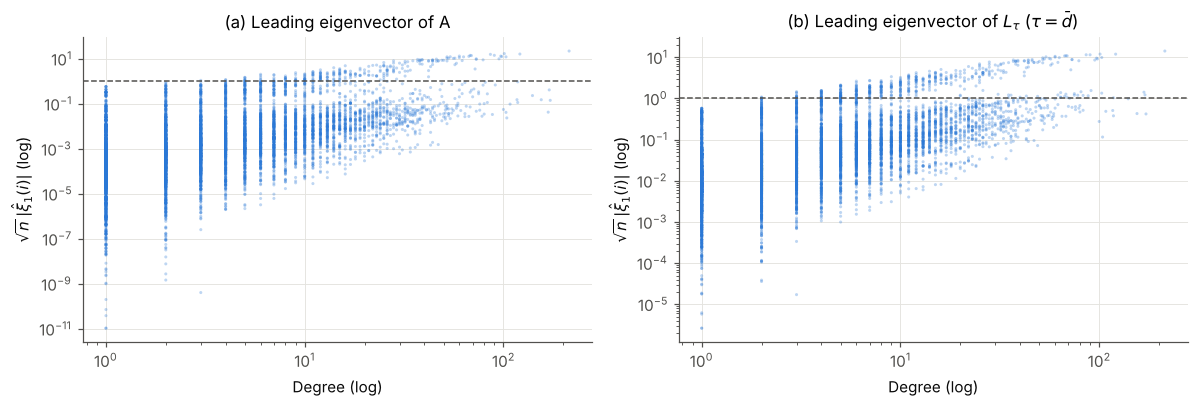

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for a, v, ttl in [(ax[0], vecs_A[:, 0], '(a) Leading eigenvector of A'),
                  (ax[1], vecs_L[:, 0], '(b) Leading eigenvector of $L_\\tau$ ($\\tau=\\bar d$)')]:
    a.scatter(deg, np.abs(v) * np.sqrt(n), s=4, alpha=0.3, color=METHOD_COLOR['SCORE+'], edgecolor='none')
    a.set_xscale('log'); a.set_yscale('log')
    a.axhline(1, color=INK2, lw=1, ls='--')
    a.set(xlabel='Degree (log)', ylabel='$\\sqrt{n}\\,|\\hat\\xi_1(i)|$ (log)', title=ttl)
fig.tight_layout(); savefig(fig, 'fig02_localization'); plt.show()

> **Interpretation.** **This is the main methodological finding about the data.** For the adjacency matrix $A$, the 50 largest entries carry ≈80% of the mass of $\hat\xi_1$ and $\hat\xi_2$ ($n\cdot$IPR ≈ 140–200 instead of ≈1–5 for a delocalized vector). Panel (a) shows that $\sqrt n|\hat\xi_1(i)|$ spans **twelve orders of magnitude** and is essentially 0 for most low-degree users. The SCORE ratios $\hat\xi_k/\hat\xi_1$ are therefore dominated by numerical noise in the periphery, and ≈39% of them hit the $\pm\log n$ truncation. The theory behind SCORE assumes $\hat\xi_1(i)\asymp\theta_i$ for all $i$ (Lec9 slides 17–21), and that assumption fails here.

Pre-PCA regularization with $\tau=\bar d$ (Lec9 slide 28) shrinks the dynamic range by roughly six orders of magnitude (panel b), and only ≈8% of ratios are truncated. The published SCORE+ default $\tau=0.1\,d_{\max}=21.4$ (Lec9 slide 43) is **too strong for this network** (≈20% truncated). With $\tau\gg d_i$ for most users, $L_\tau\approx A/\tau$ and localization partially returns. In the benchmark networks of Lec9 slide 36, $d_{\max}/\bar d$ is about 3–13. In LastFM it is **29**. We therefore use $\tau=\bar d$ and keep $0.1\,d_{\max}$ as a robustness check (§7).

### 2.2 Choosing K

Following the proposal, $K\in\{3,\dots,20\}$ is chosen **without any music data**, using
1. the **eigengap** of the main method's matrix $L_\tau$: relative gap $1-|\hat\lambda_{K+1}|/|\hat\lambda_K|$ (the same quantity SCORE+ uses);
2. **community sizes** (no degenerate tiny clusters);
3. **stability**: we delete a random 10% of edges, rerun SCORE+ on the LCC of the perturbed graph, and compute NMI with the full-data partition (mean over 10 perturbations).

In [8]:
rng = np.random.default_rng(SEED)
iu_edges = np.array(sp.triu(A).nonzero()).T
subsamples = []
for r in range(N_SUB):
    keep = iu_edges[rng.random(len(iu_edges)) < 0.9]
    Bm = sp.coo_matrix((np.ones(len(keep)), (keep[:, 0], keep[:, 1])), shape=(n, n))
    Bm = (Bm + Bm.T).tocsr()
    ncomp, comp = sp.csgraph.connected_components(Bm, directed=False)
    cc = np.where(comp == np.bincount(comp).argmax())[0]
    Bs = Bm[cc][:, cc]
    subsamples.append((cc, leading_eigs(reg_laplacian(Bs, Bs.sum() / len(cc)), 25)))

k_rows = []
for K in K_RANGE:
    lab = scoreplus_labels(vals_L, vecs_L, K)
    stab = [NMI(lab[cc], scoreplus_labels(bv, BV, K)) for cc, (bv, BV) in subsamples]
    sizes = np.bincount(lab)
    k_rows.append({'K': K, 'rel_eigengap': 1 - abs(vals_L[K]) / abs(vals_L[K - 1]), 'M (SCORE+)': scoreplus_M(vals_L, K),
                   'stability_NMI': np.mean(stab), 'stability_sd': np.std(stab),
                   'largest': sizes.max(), 'smallest': sizes.min()})
k_tab = pd.DataFrame(k_rows).round(3)
savetab(k_tab, 'tab03_K_selection')
k_tab

,K,rel_eigengap,M (SCORE+),stability_NMI,stability_sd,largest,smallest
0,3,0.015,4,0.764,0.141,4541,1193
1,4,0.006,5,0.674,0.078,3829,670
2,5,0.007,6,0.680,0.065,4014,332
3,6,0.028,7,0.789,0.023,2157,327
4,7,0.019,8,0.819,0.040,2151,140
5,8,0.003,9,0.792,0.042,2124,138
6,9,0.007,10,0.854,0.015,1885,138
7,10,0.030,11,0.854,0.017,1907,138
8,11,0.058,12,0.826,0.028,1892,138
9,12,0.018,13,0.840,0.038,1466,127


K chosen by largest relative eigengap in 3..20: 11


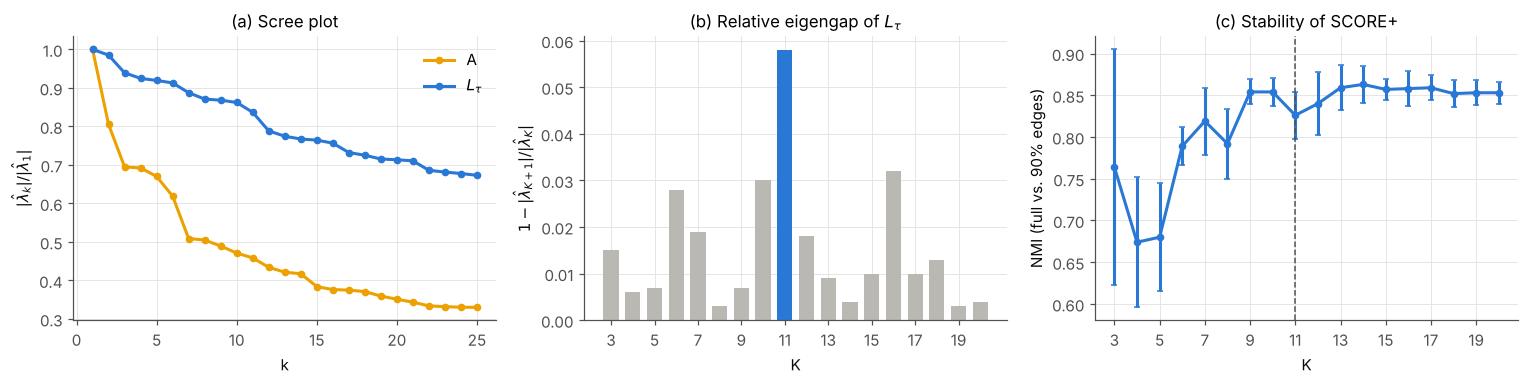

In [9]:
K_STAR = int(k_tab.loc[k_tab.rel_eigengap.idxmax(), 'K'])
print('K chosen by largest relative eigengap in 3..20:', K_STAR)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
kk = np.arange(1, 26)
ax[0].plot(kk, np.abs(vals_A[:25]) / np.abs(vals_A[0]), marker='o', ms=4, color=METHOD_COLOR['Spectral'], label='A')
ax[0].plot(kk, np.abs(vals_L[:25]) / np.abs(vals_L[0]), marker='o', ms=4, color=METHOD_COLOR['SCORE+'], label='$L_\\tau$')
ax[0].set(xlabel='k', ylabel='$|\\hat\\lambda_k| / |\\hat\\lambda_1|$', title='(a) Scree plot')
ax[0].legend()
bars = ax[1].bar(k_tab.K, k_tab.rel_eigengap, color=[METHOD_COLOR['SCORE+'] if k == K_STAR else OTHER for k in k_tab.K], width=0.7)
ax[1].set(xlabel='K', ylabel='$1-|\\hat\\lambda_{K+1}|/|\\hat\\lambda_K|$', title='(b) Relative eigengap of $L_\\tau$')
ax[2].errorbar(k_tab.K, k_tab.stability_NMI, yerr=k_tab.stability_sd, color=METHOD_COLOR['SCORE+'], marker='o', ms=4, capsize=2)
ax[2].axvline(K_STAR, color=INK2, ls='--', lw=1)
ax[2].set(xlabel='K', ylabel='NMI (full vs. 90% edges)', title='(c) Stability of SCORE+')
for a in ax[1:]:
    a.set_xticks(list(range(3, 21, 2)))
fig.tight_layout(); savefig(fig, 'fig03_K_selection'); plt.show()

> **Interpretation.** (a) The scree plot of $A$ drops quickly after a few hub-driven eigenvalues, while $L_\tau$ decays smoothly. (b) Among $K=3,\dots,20$, the largest relative eigengap of $L_\tau$ is at **$K^*=11$** (0.058, about twice the next-largest gaps at $K=10$ and $16$). (c) Stability rises from ≈0.7 for $K\le5$ to a plateau of ≈0.83–0.86 from $K\approx9$ onward, so $K=11$ is on the stable plateau. Partitions with $K=11$ have no degenerate clusters (smallest community 138 users). Because the eigengap at 10 and 16 is also visible, §7 checks that conclusions do not depend on this choice ($K\in\{5,8,11,15,20\}$). No music data were used here. SCORE+ adds an extra eigenvector ($M=K+1$) whenever the gap is below $t=0.1$, which is the case for every $K$ here: the signal is weak in the sense of Jin, Ke & Luo (2021).

### 2.3 Louvain resolution

Louvain picks its own number of communities. We first record what the **default** $\gamma=1$ gives, then scan $\gamma$ and choose the value whose median number of communities (over 5 seeds) is closest to $K^*$, so all methods are compared at a similar granularity. Stability across seeds is measured by the mean pairwise NMI of 10 runs.

In [10]:
gam_rows = []
for gam in [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0]:
    labs = [louvain_labels(G, gam, seed=SEED + s) for s in range(5)]
    Ks = [l.max() + 1 for l in labs]
    Qs = [nx.community.modularity(G, [set(nodes[l == k]) for k in range(l.max() + 1)]) for l in labs]
    gam_rows.append({'gamma': gam, 'K_median': np.median(Ks), 'K_min': min(Ks), 'K_max': max(Ks), 'modularity(γ=1)': np.mean(Qs)})
gam_tab = pd.DataFrame(gam_rows).round(3)
GAMMA = float(gam_tab.loc[(gam_tab.K_median - K_STAR).abs().idxmin(), 'gamma'])
savetab(gam_tab, 'tab04_louvain_resolution')
print('Chosen resolution γ =', GAMMA)
gam_tab

Chosen resolution γ = 0.25


,gamma,K_median,K_min,K_max,modularity(γ=1)
0,0.05,3.0,3,3,0.436
1,0.10,7.0,7,8,0.745
2,0.15,8.0,8,8,0.766
3,0.20,8.0,8,9,0.774
4,0.25,11.0,10,11,0.792
5,0.30,12.0,11,12,0.805
6,0.40,13.0,12,15,0.810
7,0.50,14.0,13,15,0.812
8,0.70,17.0,16,19,0.814
9,1.00,28.0,26,30,0.816


In [11]:
louv_runs = [louvain_labels(G, GAMMA, seed=SEED + s) for s in range(10)]
pair_nmi = [NMI(louv_runs[i], louv_runs[j]) for i in range(10) for j in range(i + 1, 10)]
print(f'Louvain (γ={GAMMA}) across 10 seeds: K = {sorted(set(l.max()+1 for l in louv_runs))}, '
      f'mean pairwise NMI = {np.mean(pair_nmi):.3f} (min {np.min(pair_nmi):.3f})')
louv_default = louvain_labels(G, 1.0)
print(f'Louvain default γ=1: K = {louv_default.max()+1}')

Louvain (γ=0.25) across 10 seeds: K = [np.int64(10), np.int64(11)], mean pairwise NMI = 0.925 (min 0.889)


Louvain default γ=1: K = 28


> **Interpretation.** With its default resolution $\gamma=1$, Louvain finds **28 communities** (modularity 0.82). Modularity is almost flat for $\gamma\in[0.3,1]$ (0.805–0.816), i.e. many partitions of different granularity are nearly equally "good". The value $\gamma=0.25$ yields 10–11 communities, matching $K^*=11$, while still reaching modularity 0.79. Across 10 seeds Louvain is quite stable (mean pairwise NMI 0.93), so the run with the main seed is representative.

### 2.4 Final partitions

community (by size),0,1,2,3,4,5,6,7,8,9,10
Spectral,6830,99,71,70,66,65,55,53,44,43,35
SCORE,1391,1160,921,777,607,581,507,444,415,365,263
SCORE+,1892,1261,1009,946,645,555,325,304,212,144,138
Louvain,1766,1574,1096,998,596,575,480,172,99,62,13


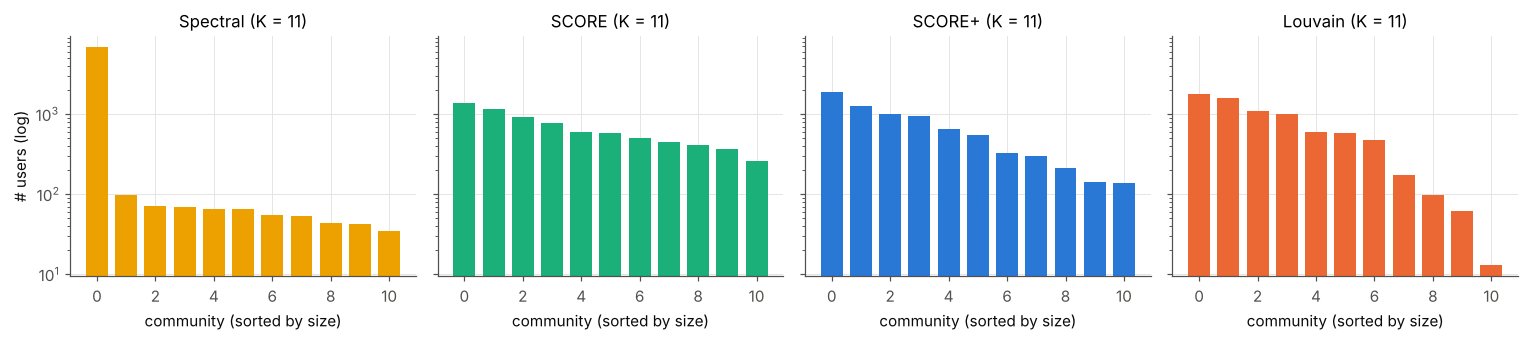

In [12]:
partitions = {
    'Spectral': spectral_labels(vecs_A, K_STAR),
    'SCORE':    score_labels(vecs_A, K_STAR),
    'SCORE+':   scoreplus_labels(vals_L, vecs_L, K_STAR),
    'Louvain':  louv_runs[0],
}
pd.DataFrame({m: l for m, l in partitions.items()}, index=nodes).rename_axis('node_id').to_csv(os.path.join(OUT_DIR, 'partitions.csv'))

size_tab = pd.DataFrame({m: pd.Series(np.bincount(l)) for m, l in partitions.items()})
size_tab.index.name = 'community (by size)'
savetab(size_tab, 'tab05_community_sizes', index=True)
display(size_tab.fillna('').T)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, m in zip(axs, METHOD_ORDER):
    s = np.bincount(partitions[m])
    a.bar(np.arange(len(s)), s, color=METHOD_COLOR[m], width=0.75)
    a.set(title=f'{m} (K = {len(s)})', xlabel='community (sorted by size)')
    a.set_yscale('log')
axs[0].set_ylabel('# users (log)')
fig.tight_layout(); savefig(fig, 'fig04_community_sizes'); plt.show()

> **Interpretation.** **Spectral clustering on $A$ fails in the way the DCBM predicts:** one giant cluster holds 6,830 users (92%), and the remaining ten clusters have only 35–99 users each. These small clusters are formed around hubs (see §6). SCORE, SCORE+ and Louvain all produce balanced partitions (largest 1,391–1,892, smallest 13–263). Louvain's smallest community (13) is a small peripheral group, and SCORE+'s smallest is 138.

## 3. Music similarity

Let $F_i$ be the set of artists liked by user $i$. Similarity is the Jaccard index $S_{ij}=|F_i\cap F_j|/|F_i\cup F_j|$, computed for all $\binom{n}{2}$ pairs at once via the sparse product $XX^\top$ (intersections) and $|F_i|+|F_j|-|F_i\cap F_j|$ (unions). The diagonal is set to 0 and never used.

In [13]:
def jaccard_matrix(Xm):
    inter = (Xm @ Xm.T).toarray().astype(np.float32)
    a = np.asarray(Xm.sum(1)).ravel().astype(np.float32)
    union = a[:, None] + a[None, :] - inter
    S = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
    np.fill_diagonal(S, 0.0)
    return S

t0 = time.time()
S = jaccard_matrix(X)
iu = np.triu_indices(n, 1)
s_all = S[iu]
print(f'Jaccard matrix {S.shape} computed in {time.time()-t0:.1f}s')
print(f'Mean pairwise similarity: {s_all.mean():.4f} | median {np.median(s_all):.4f} | 99th pct {np.quantile(s_all, .99):.4f}')
# similarity of directly connected pairs (friends) vs all pairs
eu, ev = sp.triu(A).nonzero()
print(f'Mean similarity of friends (edges): {S[eu, ev].mean():.4f}  ->  {S[eu, ev].mean()/s_all.mean():.2f}x the overall mean')
del s_all

Jaccard matrix (7431, 7431) computed in 10.9s


Mean pairwise similarity: 0.0625 | median 0.0516 | 99th pct 0.2134
Mean similarity of friends (edges): 0.1490  ->  2.38x the overall mean


> **Interpretation.** Taste similarity is low on average (mean Jaccard 0.063, i.e. two random users share about 6% of their combined artist set) and right-skewed. A first descriptive signal that "social = musical": **directly connected friends are 2.4× more similar** (mean 0.149) than random pairs. The question for the community analysis is whether this local homophily scales up to whole communities, after controlling for degree, activity and country.

## 4. Main test: is a social circle also a music circle?

**Test statistic.** For a partition with communities $C_1,\dots,C_K$ of sizes $n_k$, let $W=Z^\top SZ$ ($Z$ = $n\times K$ membership matrix), so $W_{kl}$ is the total similarity between communities $k$ and $l$. Then
$$\bar S_{kk}=\frac{W_{kk}}{n_k(n_k-1)},\qquad \bar S_{kl}=\frac{W_{kl}}{n_kn_l},\qquad
T=\underbrace{\frac1K\sum_k \bar S_{kk}}_{\bar S_{\text{same}}}-\underbrace{\binom K2^{-1}\sum_{k<l}\bar S_{kl}}_{\bar S_{\text{diff}}}.$$
Averaging within each community first and then across communities means large communities do not dominate (proposal §5). We also report the ratio $\bar S_{\text{same}}/\bar S_{\text{diff}}$ as an interpretable effect size.

**Stratified permutation test.** Keep the network and the partition fixed, and shuffle users' music records **within strata** of similar degree × number of artists (5 × 5 quantile bins = 25 strata). This is the null "community membership carries no information about taste beyond degree and activity". Highly active users have both more links and more artists, which could create spurious similarity. Stratifying holds that constant.

*Computational shortcut.* Permuting music records by $\pi$ gives $S^\pi=P_\pi SP_\pi^\top$, and $Z^\top S^\pi Z=(P_\pi^\top Z)^\top S(P_\pi^\top Z)$. So permuting music is **exactly** equivalent to permuting community labels within the same strata while $S$ stays fixed. Each permutation then costs one dense-times-thin product $S\,Z_\pi$.

Pairs share users, so they are not independent and a $t$-test would be invalid. The permutation null respects this dependence. We report the permutation $p$-value $(1+\#\{T^{(b)}\ge T\})/(B+1)$ and the standardized effect $z=(T-\text{mean}(T^{(b)}))/\text{sd}(T^{(b)})$.

In [14]:
def onehot(lab):
    Z = np.zeros((len(lab), lab.max() + 1), dtype=np.float32)
    Z[np.arange(len(lab)), lab] = 1
    return Z

def T_stat(S, lab, full=False):
    Z = onehot(lab); W = Z.T @ (S @ Z); nk = Z.sum(0).astype(np.float64)
    ok = nk >= 2
    within = np.diag(W)[ok] / (nk[ok] * (nk[ok] - 1))
    Bt = W / np.outer(nk, nk)
    K = len(nk); iuK = np.triu_indices(K, 1)
    same, diff = within.mean(), Bt[iuK].mean()
    if full:
        return dict(T=same - diff, S_same=same, S_diff=diff, ratio=same / diff,
                    within=np.diag(W) / np.maximum(nk * (nk - 1), 1), between=Bt, sizes=nk)
    return same - diff

def T_pairs(S, lab, full=False):
    """Alternative (pair-weighted) statistic: mean over all same-community pairs minus mean over all cross pairs."""
    Z = onehot(lab); W = Z.T @ (S @ Z); nk = Z.sum(0).astype(np.float64)
    same_sum, same_cnt = np.trace(W), (nk * (nk - 1)).sum()
    tot_sum, tot_cnt = W.sum(), len(lab) * (len(lab) - 1)
    same, diff = same_sum / same_cnt, (tot_sum - same_sum) / (tot_cnt - same_cnt)
    return dict(T=same - diff, S_same=same, S_diff=diff, ratio=same / diff) if full else same - diff

def make_strata(*vars_, q=5):
    code = np.zeros(n, dtype=int)
    for v in vars_:
        code = code * q + pd.qcut(pd.Series(v).rank(method='first'), q, labels=False).values
    return code

def perm_test(S, lab, strata, B, seed=SEED, stat=T_stat):
    r = np.random.default_rng(seed)
    groups = [np.where(strata == s)[0] for s in np.unique(strata)]
    T_obs = stat(S, lab)
    null = np.empty(B)
    for b in range(B):
        lp = lab.copy()
        for g in groups:
            lp[g] = lab[g[r.permutation(len(g))]]
        null[b] = stat(S, lp)
    return dict(T=T_obs, null=null, p=(1 + (null >= T_obs).sum()) / (B + 1),
                z=(T_obs - null.mean()) / null.std(), null_mean=null.mean(), null_sd=null.std())

STRATA_DA = make_strata(deg, n_art)
print('Strata (degree x activity):', len(np.unique(STRATA_DA)), '| sizes from', np.bincount(STRATA_DA).min(), 'to', np.bincount(STRATA_DA).max())

Strata (degree x activity): 25 | sizes from 135 to 460


In [15]:
t0 = time.time()
main_res = {m: perm_test(S, l, STRATA_DA, B_MAIN) for m, l in partitions.items()}
print(f'{len(partitions)} x {B_MAIN} permutations in {time.time()-t0:.0f}s')

main_tab = pd.DataFrame([{
    'Method': m, 'K': partitions[m].max() + 1,
    'S_same': T_stat(S, partitions[m], True)['S_same'], 'S_diff': T_stat(S, partitions[m], True)['S_diff'],
    'T': r['T'], 'ratio S_same/S_diff': T_stat(S, partitions[m], True)['ratio'],
    'null mean': r['null_mean'], 'null sd': r['null_sd'], 'z': r['z'], 'p (perm)': r['p'],
} for m, r in main_res.items()]).set_index('Method').loc[METHOD_ORDER]
savetab(main_tab.round(5), 'tab06_main_test', index=True)
main_tab.round(4)

4 x 1000 permutations in 192s


,K,S_same,S_diff,T,ratio S_same/S_diff,null mean,null sd,z,p (perm)
Method,,,,,,,,,
Spectral,11,0.1328,0.0860,0.0468,1.5439,0.0019,0.0004,119.3650,0.001
SCORE,11,0.0763,0.0609,0.0154,1.2533,0.0008,0.0001,291.6426,0.001
SCORE+,11,0.0801,0.0589,0.0212,1.3599,0.0006,0.0001,318.3277,0.001
Louvain,11,0.0790,0.0592,0.0198,1.3337,0.0009,0.0004,50.6389,0.001


> **Interpretation.** **All four partitions show significantly more similar taste within communities than between** ($p\approx0.001$, the smallest attainable with $B=1000$; none of the 1,000 permuted statistics reached the observed $T$). For the main method **SCORE+**, the mean within-community similarity is 0.080 vs. 0.059 between communities, a **36% lift** ($T=0.021$). The degree × activity null is centred at $T\approx0.0006$, so almost none of the effect is explained by degree or activity, and the observed value lies ≈318 null standard deviations away. Louvain (lift 33%) and SCORE (25%) agree.

Spectral clustering shows the largest $T$ (lift 54%), but this should not be read as "better communities". Its statistic averages over one giant cluster plus ten tiny hub-centred clusters whose members are unusually similar. When every same-community *pair* is weighted equally (§7, pair-weighted $T$), Spectral's effect turns **negative** ($T=-0.014$), while SCORE, SCORE+ and Louvain stay positive (≈0.016–0.018). The community-averaged statistic is sensitive to many small clusters, which is one more reason to prefer degree-corrected methods.

### 4.1 Which communities share taste? (SCORE+)

,size,within-community similarity,mean similarity to other communities,lift (within / other),mean degree,top country share
community,,,,,,
0,1892,0.074,0.062,1.186,7.221,0.527
1,1261,0.089,0.062,1.450,7.309,0.863
2,1009,0.081,0.061,1.326,6.948,0.746
3,946,0.084,0.065,1.304,7.505,0.462
4,645,0.050,0.047,1.073,5.329,0.828
5,555,0.060,0.049,1.220,6.243,0.550
6,325,0.081,0.061,1.335,10.542,0.714
7,304,0.077,0.058,1.326,8.536,0.875
8,212,0.110,0.059,1.853,9.646,0.632


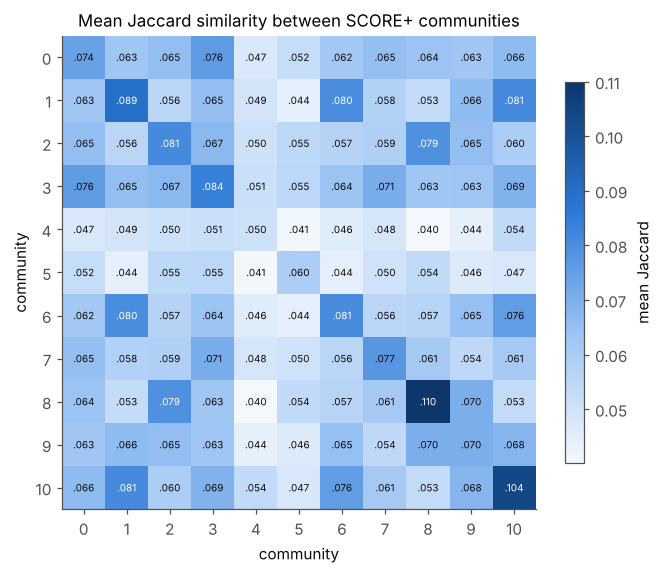

In [16]:
res_sp = T_stat(S, partitions['SCORE+'], full=True)
Kp = len(res_sp['sizes'])
Mmat = res_sp['between'].copy(); np.fill_diagonal(Mmat, res_sp['within'])
off = ~np.eye(Kp, dtype=bool)
comm_tab = pd.DataFrame({
    'size': res_sp['sizes'].astype(int),
    'within-community similarity': res_sp['within'],
    'mean similarity to other communities': np.array([Mmat[k, off[k]].mean() for k in range(Kp)]),
})
comm_tab['lift (within / other)'] = comm_tab.iloc[:, 1] / comm_tab.iloc[:, 2]
comm_tab['mean degree'] = [deg[partitions['SCORE+'] == k].mean() for k in range(Kp)]
comm_tab['top country share'] = [pd.Series(country[partitions['SCORE+'] == k]).value_counts(normalize=True).iloc[0] for k in range(Kp)]
comm_tab.index.name = 'community'
savetab(comm_tab.round(4), 'tab07_scoreplus_communities', index=True)
display(comm_tab.round(3))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(Mmat, cmap=mpl.colors.LinearSegmentedColormap.from_list('b', ['#f4f8fd', '#9ec5f4', '#2a78d6', '#0d366b']))
ax.set_xticks(range(Kp)); ax.set_yticks(range(Kp)); ax.grid(False)
for i in range(Kp):
    for j in range(Kp):
        ax.text(j, i, f'{Mmat[i,j]:.3f}'[1:], ha='center', va='center', fontsize=6.5,
                color='white' if Mmat[i, j] > Mmat.min() + 0.55 * (Mmat.max() - Mmat.min()) else INK)
ax.set(xlabel='community', ylabel='community', title='Mean Jaccard similarity between SCORE+ communities')
fig.colorbar(im, ax=ax, shrink=0.8, label='mean Jaccard')
fig.tight_layout(); savefig(fig, 'fig05_similarity_matrix'); plt.show()

> **Interpretation.** Every SCORE+ community is more similar internally than to the rest of the network (lift 1.07–1.85). The tight-taste communities are small-to-mid sized (C8: 212 users, within-similarity 0.110, lift 1.85; C10: 138 users, 0.104, lift 1.64). The two weakest (C4 and C5, lift 1.07 and 1.22) also have the **lowest mean degrees** (5.3 and 6.2): loosely connected groups are also less musically coherent. The block matrix is not purely diagonal. Some pairs of communities (e.g. C1–C6–C10, C2–C8) share taste with each other, which suggests a coarser "taste geography" above the community level.

## 5. Is it just country?

Users in the same country might both befriend each other and like the same (local) artists. Then communities would "share taste" only because they are country groups. We check this in two ways:
1. **How much do communities align with countries?** NMI between each partition and the country labels.
2. **Country-stratified permutation test.** Shuffle music records only **within the same country**. Under this null, any similarity explained by country is preserved, so a significant $T$ means communities share taste *beyond* what country explains. We also report the share of the observed $T$ that country alone reproduces: $\text{mean}(T^{(b)}_{\text{country}})/T$.

In [17]:
STRATA_C = pd.factorize(country)[0]
STRATA_CDA = STRATA_C * 1000 + make_strata(deg, n_art, q=3)   # country x degree x activity (3x3)
t0 = time.time()
country_res = {m: perm_test(S, l, STRATA_C, B_MAIN, seed=SEED + 1) for m, l in partitions.items()}
country_res2 = {m: perm_test(S, l, STRATA_CDA, B_ROBUST, seed=SEED + 2) for m, l in partitions.items()}
print(f'done in {time.time()-t0:.0f}s')
country_tab = pd.DataFrame([{
    'Method': m, 'NMI with country': NMI(country, partitions[m]), 'T': r['T'],
    'null mean (within-country)': r['null_mean'], 'share of T explained by country': r['null_mean'] / r['T'],
    'z (within-country)': r['z'], 'p (within-country)': r['p'],
    'z (country x deg x activity)': country_res2[m]['z'], 'p (country x deg x activity)': country_res2[m]['p'],
} for m, r in country_res.items()]).set_index('Method').loc[METHOD_ORDER]
savetab(country_tab.round(5), 'tab08_country_check', index=True)
print('Reference: T if the partition were the 18 countries themselves =', round(float(T_stat(S, STRATA_C)), 4))
country_tab.round(4)

done in 230s
Reference: T if the partition were the 18 countries themselves = 0.0192


,NMI with country,T,null mean (within-country),share of T explained by country,z (within-country),p (within-country),z (country x deg x activity),p (country x deg x activity)
Method,,,,,,,,
Spectral,0.1403,0.0468,0.0175,0.3730,28.3914,0.001,18.1391,0.0050
SCORE,0.5071,0.0154,0.0100,0.6482,38.4362,0.001,38.6358,0.0050
SCORE+,0.5245,0.0212,0.0110,0.5200,64.3054,0.001,62.3614,0.0050
Louvain,0.6347,0.0198,0.0142,0.7190,6.5846,0.001,3.6389,0.0149


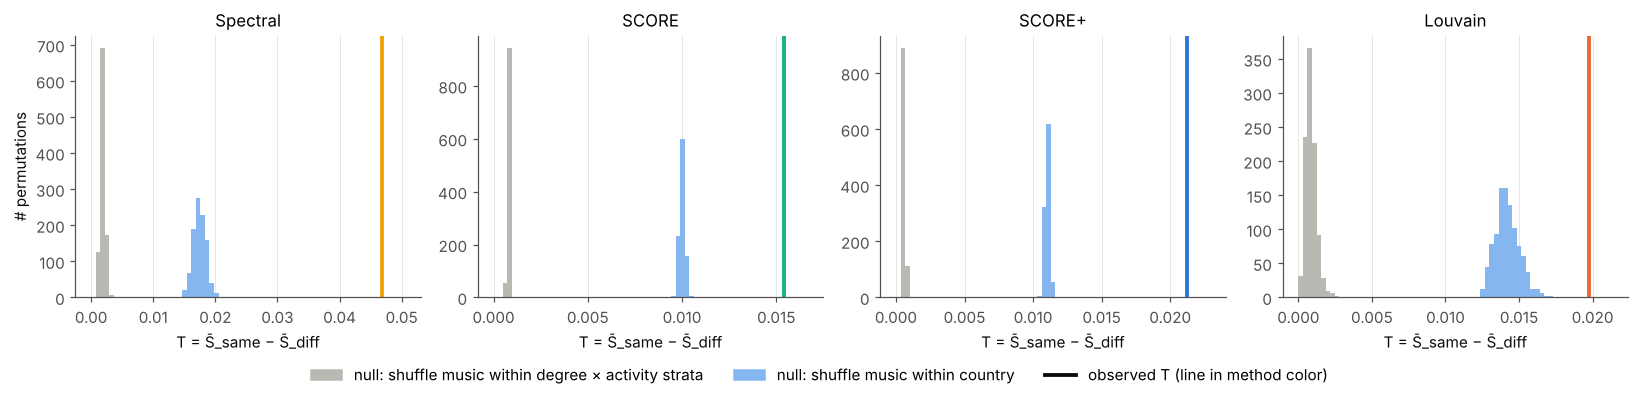

In [18]:
# Headline figure: observed T vs. the two null distributions, for each method
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for a, m in zip(axs, METHOD_ORDER):
    r1, r2 = main_res[m], country_res[m]
    allv = np.concatenate([r1['null'], r2['null'], [r1['T']]])
    bins = np.linspace(0, allv.max() * 1.08, 70)
    a.hist(r1['null'], bins=bins, color=OTHER, label='null: shuffle within degree×activity')
    a.hist(r2['null'], bins=bins, color='#86b6ef', label='null: shuffle within country')
    a.axvline(r1['T'], color=METHOD_COLOR[m], lw=2.5, label='observed T')
    a.set(title=m, xlabel='T = S̄_same − S̄_diff')
    a.grid(axis='y', visible=False)
axs[0].set_ylabel('# permutations')
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
h = [Patch(color=OTHER), Patch(color='#86b6ef'), Line2D([0], [0], color=INK, lw=2.5)]
l = ['null: shuffle music within degree × activity strata', 'null: shuffle music within country', 'observed T (line in method color)']
fig.legend(h, l, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(); savefig(fig, 'fig06_permutation_nulls'); plt.show()

> **Interpretation.** **Country is an important confounder, but it does not explain everything.** Communities align with countries to a moderate degree (NMI 0.51–0.64 for SCORE, SCORE+ and Louvain; most SCORE+ communities are 45–91% one country). Shuffling music **within country** reproduces about **half of the SCORE+ effect** (mean null $T$ = 0.011 vs. observed 0.021; 52%). For reference, using the 18 countries themselves as the partition gives $T=0.019$. Still, the observed $T$ lies far above the within-country null for every method ($p\approx0.001$; SCORE+ $z=64$). The result holds when we stratify on country × degree × activity jointly. So **within the same country, users in the same social community still share more taste**.

Louvain is the exception that proves the rule. It is the most country-aligned partition (NMI 0.63), country explains 72% of its $T$, and its residual effect is the weakest ($z=6.6$; $z=3.6$, $p=0.015$ under the joint country × degree × activity strata with $B=200$). In the figure, every observed line (method color) sits far to the right of both null distributions, and the gap between the grey and the blue null is the part attributable to country.

## 6. Does the method matter?

We compare the partitions with each other (NMI) and with country, and look at **where high-degree users go**. If a method clusters by popularity $\theta_i$ rather than by community, hubs will be concentrated in a few (small) communities.

In [19]:
labs_cmp = {**partitions, 'Louvain (γ=1)': louv_default, 'Country': country}
names = list(labs_cmp)
nmi_mat = pd.DataFrame([[NMI(labs_cmp[a], labs_cmp[b]) for b in names] for a in names], index=names, columns=names)
savetab(nmi_mat.round(3), 'tab09_nmi_matrix', index=True)

hub = deg >= np.quantile(deg, 0.99)
hub_rows = []
for m in METHOD_ORDER:
    l = partitions[m]; sizes = np.bincount(l)
    hub_comm = pd.Series(l[hub]).value_counts()
    hub_rows.append({'Method': m,
                     '# communities containing top-1% hubs': len(hub_comm),
                     '% of hubs in communities with < 5% of users': 100 * np.mean(sizes[l[hub]] < 0.05 * n),
                     'corr(community size, mean degree)': pd.Series(sizes).corr(pd.Series([deg[l == k].mean() for k in range(len(sizes))]), method='spearman'),
                     'max mean degree / overall mean degree': max(deg[l == k].mean() for k in range(len(sizes))) / deg.mean()})
hub_tab = pd.DataFrame(hub_rows).set_index('Method')
savetab(hub_tab.round(3), 'tab10_hub_placement', index=True)

summary_tab = main_tab[['K', 'T', 'ratio S_same/S_diff', 'z', 'p (perm)']].join(
    country_tab[['z (within-country)', 'p (within-country)', 'share of T explained by country', 'NMI with country']])
summary_tab['NMI with SCORE+'] = [NMI(partitions[m], partitions['SCORE+']) for m in summary_tab.index]
savetab(summary_tab.round(4), 'tab11_method_comparison', index=True)
display(summary_tab.round(3))
display(hub_tab.round(3))

,K,T,ratio S_same/S_diff,z,p (perm),z (within-country),p (within-country),share of T explained by country,NMI with country,NMI with SCORE+
Method,,,,,,,,,,
Spectral,11,0.047,1.544,119.365,0.001,28.391,0.001,0.373,0.140,0.154
SCORE,11,0.015,1.253,291.643,0.001,38.436,0.001,0.648,0.507,0.622
SCORE+,11,0.021,1.360,318.328,0.001,64.305,0.001,0.520,0.524,1.000
Louvain,11,0.020,1.334,50.639,0.001,6.585,0.001,0.719,0.635,0.636


,# communities containing top-1% hubs,% of hubs in communities with < 5% of users,"corr(community size, mean degree)",max mean degree / overall mean degree
Method,,,,
Spectral,10,90.667,-0.091,7.367
SCORE,10,13.333,-0.427,1.640
SCORE+,9,16.000,-0.309,1.448
Louvain,6,0.000,-0.082,1.285


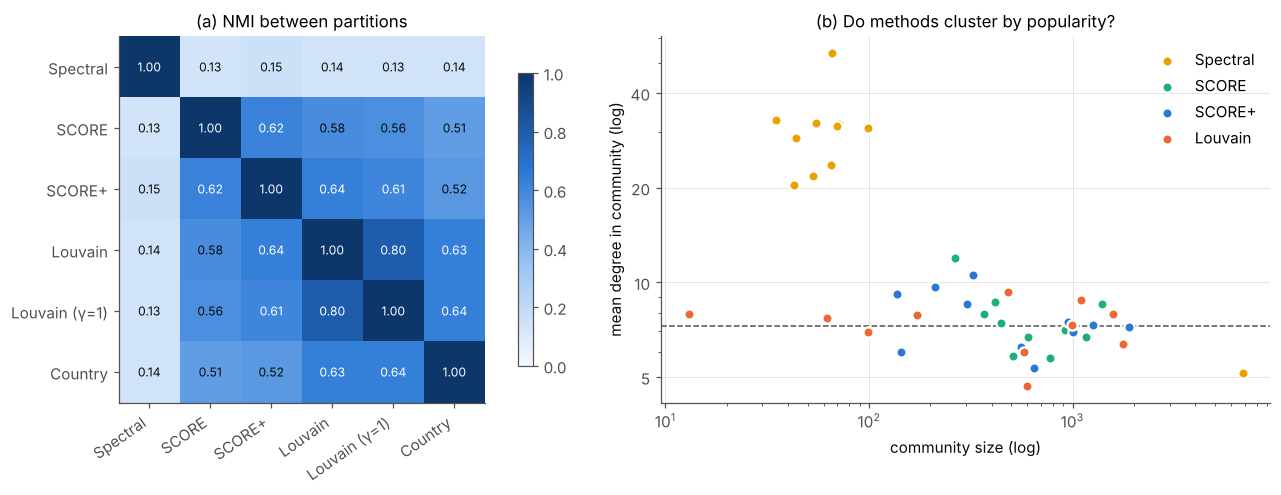

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
im = ax[0].imshow(nmi_mat.values, vmin=0, vmax=1, cmap=mpl.colors.LinearSegmentedColormap.from_list('b', ['#f4f8fd', '#9ec5f4', '#2a78d6', '#0d366b']))
ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, rotation=35, ha='right'); ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names)
ax[0].grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax[0].text(j, i, f'{nmi_mat.values[i,j]:.2f}', ha='center', va='center', fontsize=8, color='white' if nmi_mat.values[i, j] > .6 else INK)
ax[0].set_title('(a) NMI between partitions'); fig.colorbar(im, ax=ax[0], shrink=0.8)
for m in METHOD_ORDER:
    l = partitions[m]; sizes = np.bincount(l)
    md_ = [deg[l == k].mean() for k in range(len(sizes))]
    ax[1].scatter(sizes, md_, s=45, color=METHOD_COLOR[m], label=m, edgecolor='white', linewidth=1.5, zorder=3)
ax[1].axhline(deg.mean(), color=INK2, ls='--', lw=1)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter()); ax[1].yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax[1].set_yticks([5, 10, 20, 40])
ax[1].set(xlabel='community size (log)', ylabel='mean degree in community (log)', title='(b) Do methods cluster by popularity?')
ax[1].legend()
fig.tight_layout(); savefig(fig, 'fig07_method_comparison'); plt.show()

> **Interpretation.** - **SCORE, SCORE+ and Louvain largely agree** (pairwise NMI 0.58–0.64) and give the same qualitative conclusion. **Spectral clustering on $A$ is the outlier** (NMI ≈0.14 with everything, including country).
- **Hub placement (panel b):** Spectral's ten small clusters have mean degrees 20–55, i.e. 3–7× the network average, and 91% of the top-1% hubs sit in communities holding <5% of users. Spectral clustering is grouping users **by popularity** ($\theta_i$), not by community, as the DCBM analysis in Lec9 predicts. The degree-corrected methods spread hubs across communities, and all their community mean degrees are within 0.6–1.6× the average.
- **Does the method matter for the conclusion?** For the direction of the answer, no: every method finds $T>0$ with $p\approx0.001$. For its interpretation, yes. Spectral's apparently large effect comes from hub clusters and reverses under pair weighting. Louvain's partition is so country-aligned that most of its effect is country. SCORE+ gives the clearest evidence of taste sharing beyond country.

## 7. Robustness

Each check uses $B=200$ permutations within degree × activity strata (and within country for the main method). With $B=200$ the smallest attainable $p$-value is $1/201\approx0.005$, so we focus on $T$, the ratio and $z$.

1. **Number of communities**: $K\in\{5, 8, 11, 15, 20\}$ for the spectral methods; $\gamma\in\{0.1, 0.3, 0.5, 1.0\}$ for Louvain.
2. **Regularization** of SCORE+: $\tau\in\{0.3\bar d,\ \bar d,\ 3\bar d,\ 0.1\,d_{\max}\}$.
3. **Removing the most popular artists** (top 1%, 5%, 10% by number of fans) and recomputing $S$. If shared taste were driven only by a handful of global hits, $T$ would vanish.
4. **Alternative definition**: pair-weighted $T$ (every same-community pair counts equally).

In [21]:
rob = []
def add(check, setting, method, lab, Sm=S, strata=STRATA_DA, stat=T_stat):
    r = perm_test(Sm, lab, strata, B_ROBUST, seed=SEED + 7, stat=stat)
    full = stat(Sm, lab, full=True)
    rob.append({'check': check, 'setting': setting, 'method': method, 'K': lab.max() + 1, 'T': r['T'],
                'ratio': full['ratio'], 'z': r['z'], 'p': r['p']})
t0 = time.time()
# (1) K / gamma
for K in [5, 8, 11, 15, 20]:
    add('K', K, 'Spectral', spectral_labels(vecs_A, K))
    add('K', K, 'SCORE', score_labels(vecs_A, K))
    add('K', K, 'SCORE+', scoreplus_labels(vals_L, vecs_L, K))
for gam in [0.1, 0.3, 0.5, 1.0]:
    add('gamma', gam, 'Louvain', louvain_labels(G, gam))
# (2) tau for SCORE+
for name, tau in [('0.3 d̄', 0.3 * deg.mean()), ('d̄', deg.mean()), ('3 d̄', 3 * deg.mean()), ('0.1 d_max', 0.1 * deg.max())]:
    v, V = leading_eigs(reg_laplacian(A, tau), 25)
    add('tau', name, 'SCORE+', scoreplus_labels(v, V, K_STAR))
print(f'(1)-(2) done in {time.time()-t0:.0f}s')

(1)-(2) done in 230s


In [22]:
t0 = time.time()
order = np.argsort(-art_pop)
for frac in [0.01, 0.05, 0.10]:
    drop = order[:int(np.ceil(frac * X.shape[1]))]
    keep = np.setdiff1d(np.arange(X.shape[1]), drop)
    S_r = jaccard_matrix(X[:, keep])
    for m in METHOD_ORDER:
        add('drop popular artists', f'top {int(frac*100)}%', m, partitions[m], Sm=S_r)
    del S_r
for m in METHOD_ORDER:
    add('pair-weighted T', '-', m, partitions[m], stat=T_pairs)
print(f'(3)-(4) done in {time.time()-t0:.0f}s')
rob_tab = pd.DataFrame(rob)
savetab(rob_tab.round(5), 'tab12_robustness')
rob_tab.round(4)

(3)-(4) done in 178s


,check,setting,method,K,T,ratio,z,p
0,K,5,Spectral,5,0.0341,1.3783,55.1092,0.005
1,K,5,SCORE,5,0.0133,1.2118,197.8877,0.005
2,K,5,SCORE+,5,0.0133,1.2120,241.4126,0.005
3,K,8,Spectral,8,0.0485,1.5783,93.5842,0.005
4,K,8,SCORE,8,0.0132,1.2138,269.3855,0.005
5,K,8,SCORE+,8,0.0159,1.2510,227.8193,0.005
6,K,11,Spectral,11,0.0468,1.5439,114.2748,0.005
7,K,11,SCORE,11,0.0154,1.2533,303.4389,0.005
8,K,11,SCORE+,11,0.0212,1.3599,321.9667,0.005
9,K,15,Spectral,15,0.0502,1.5873,118.7416,0.005


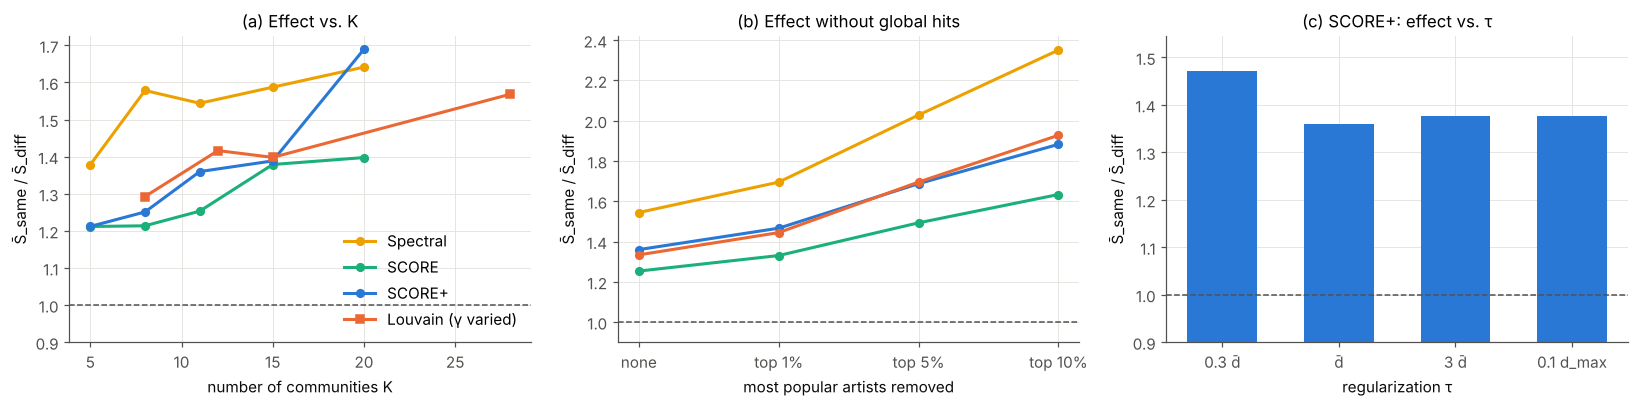

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
rk = rob_tab[rob_tab.check == 'K']
for m in ['Spectral', 'SCORE', 'SCORE+']:
    d_ = rk[rk.method == m]
    axs[0].plot(d_.setting.astype(int), d_.ratio, marker='o', ms=5, color=METHOD_COLOR[m], label=m)
d_ = rob_tab[rob_tab.check == 'gamma']
axs[0].plot(d_.K, d_.ratio, marker='s', ms=5, color=METHOD_COLOR['Louvain'], label='Louvain (γ varied)')
axs[0].axhline(1, color=INK2, lw=1, ls='--')
axs[0].set(xlabel='number of communities K', ylabel='S̄_same / S̄_diff', title='(a) Effect vs. K')
axs[0].legend()
dp = rob_tab[rob_tab.check == 'drop popular artists']
base = main_tab['ratio S_same/S_diff']
xs = ['none', 'top 1%', 'top 5%', 'top 10%']
for m in METHOD_ORDER:
    y = [base[m]] + list(dp[dp.method == m].ratio)
    axs[1].plot(xs, y, marker='o', ms=5, color=METHOD_COLOR[m], label=m)
axs[1].axhline(1, color=INK2, lw=1, ls='--')
axs[1].set(xlabel='most popular artists removed', ylabel='S̄_same / S̄_diff', title='(b) Effect without global hits')
dt = rob_tab[rob_tab.check == 'tau']
axs[2].bar(dt.setting.astype(str), dt.ratio, color=METHOD_COLOR['SCORE+'], width=0.6)
axs[2].axhline(1, color=INK2, lw=1, ls='--')
axs[2].set(xlabel='regularization τ', ylabel='S̄_same / S̄_diff', title='(c) SCORE+: effect vs. τ')
for a in axs: a.set_ylim(bottom=0.9)
fig.tight_layout(); savefig(fig, 'fig08_robustness'); plt.show()

> **Interpretation.** - **(a) Number of communities.** For SCORE, SCORE+ and Louvain the lift grows smoothly with granularity (≈1.2 at $K=5$ to 1.4–1.7 at $K=20$; Louvain at $\gamma=1$, $K=28$: 1.57). Finer communities are more homogeneous, but the effect is present at every $K$ with $p\approx0.005$ (the minimum for $B=200$).
- **(b) Removing global hits strengthens the effect.** Dropping the 1%, 5% and 10% most popular artists *raises* the SCORE+ lift from 1.36 to 1.47, 1.69 and 1.88 (same pattern for all methods). Shared taste within communities is driven by **less mainstream artists**, not by everyone liking the same global stars.
- **(c) Regularization.** SCORE+ gives lift 1.36–1.47 for $\tau\in\{0.3\bar d,\bar d,3\bar d,0.1d_{\max}\}$, so the conclusion does not hinge on $\tau$.
- **Alternative statistic.** Pair-weighted $T$ is positive and significant for SCORE, SCORE+ and Louvain, but **negative for Spectral** (see §4).

## 8. Network visualizations (for the webpage)

(a) The full network drawn with a Fruchterman–Reingold layout (igraph; cached in `outputs/layout.npy`), colored by SCORE+ community. The 8 largest communities get distinct colors and the rest are grey. (b) The **community graph**: one node per SCORE+ community (area ∝ size, color = within-community music similarity), with edge width ∝ number of follow links between communities.

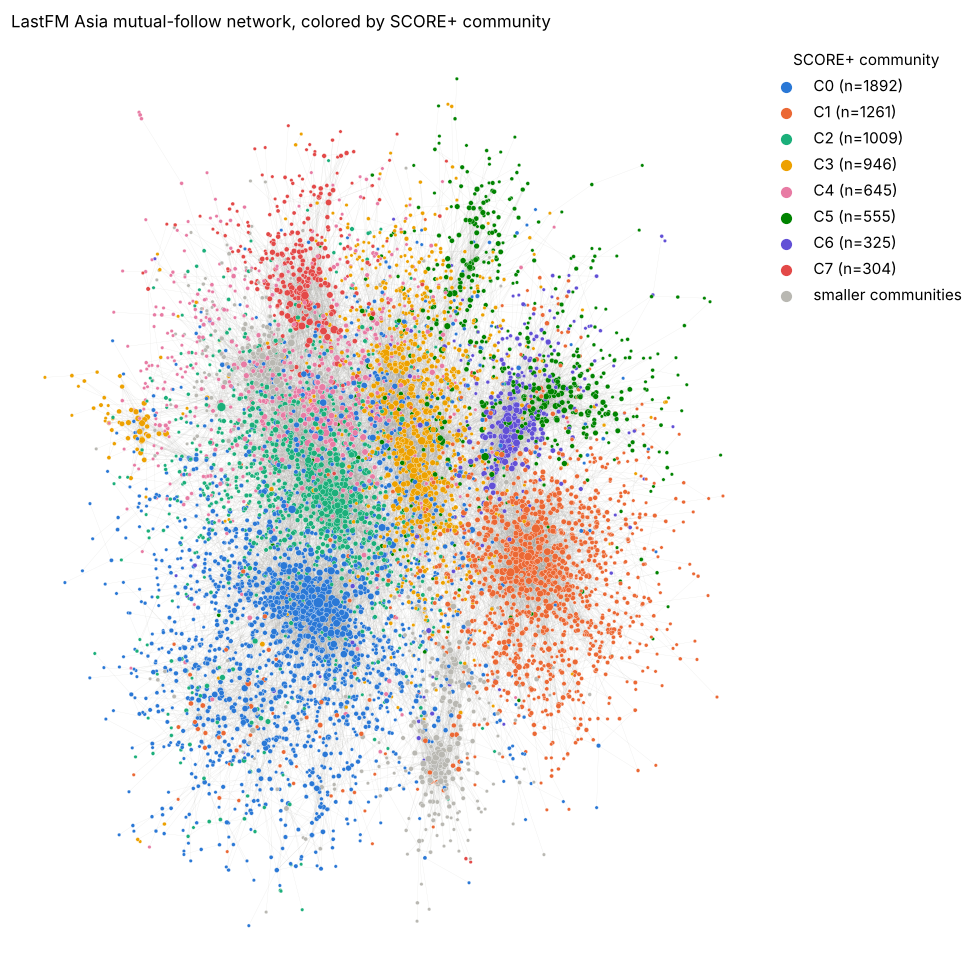

In [24]:
lay_path = os.path.join(OUT_DIR, 'layout.npy')
if os.path.exists(lay_path):
    pos = np.load(lay_path)
else:
    random.seed(SEED)
    gi = ig.Graph(n=n, edges=list(zip(*sp.triu(A).nonzero())))
    pos = np.array(gi.layout_fruchterman_reingold(niter=1500).coords)
    np.save(lay_path, pos)

lab = partitions['SCORE+']
col = np.array([CAT8[k] if k < 8 else OTHER for k in lab])
fig, ax = plt.subplots(figsize=(9, 9))
eu, ev = sp.triu(A).nonzero()
segs = np.stack([pos[eu], pos[ev]], axis=1)
ax.add_collection(mpl.collections.LineCollection(segs, colors='#9a9993', linewidths=0.15, alpha=0.25, zorder=1))
ax.scatter(pos[:, 0], pos[:, 1], s=2 + 3 * np.sqrt(deg), c=col, edgecolor='white', linewidth=0.2, zorder=2)
for k in range(min(8, lab.max() + 1)):
    ax.scatter([], [], s=40, color=CAT8[k], label=f'C{k} (n={np.sum(lab==k)})')
if lab.max() >= 8:
    ax.scatter([], [], s=40, color=OTHER, label='smaller communities')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), title='SCORE+ community')
ax.set_axis_off(); ax.set_title('LastFM Asia mutual-follow network, colored by SCORE+ community', loc='left')
fig.tight_layout(); savefig(fig, 'fig09_network'); plt.show()

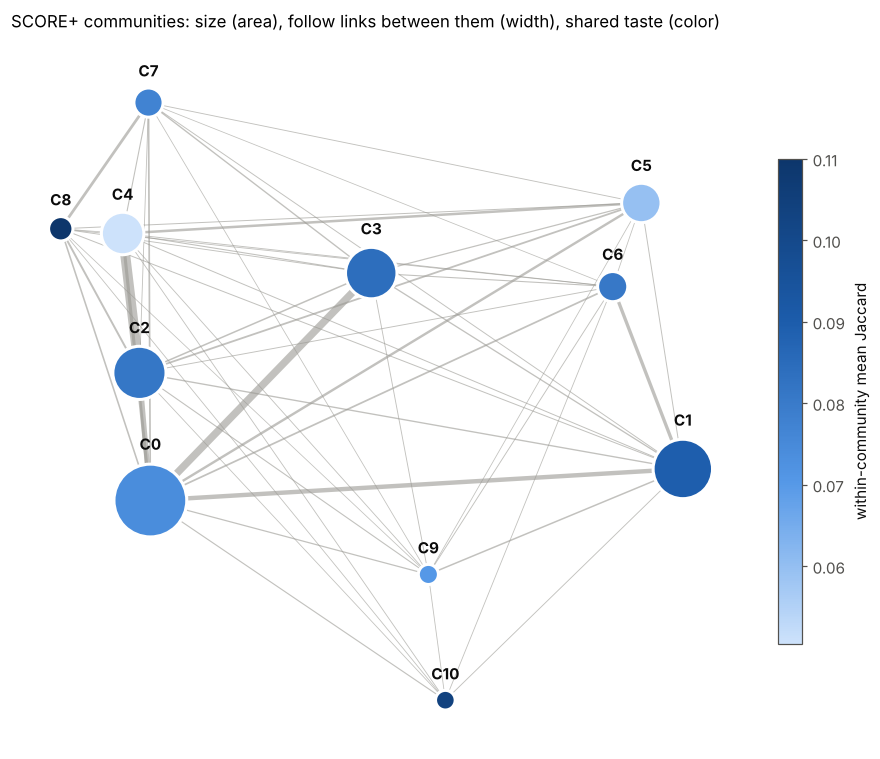

In [25]:
Zc = onehot(lab)
Ec = (Zc.T @ (A @ Zc)).astype(float)       # follow links between communities (diag counts each edge twice)
cent = np.array([pos[lab == k].mean(0) for k in range(Kp)])
fig, ax = plt.subplots(figsize=(8.5, 7))
wmax = max(Ec[i, j] for i in range(Kp) for j in range(Kp) if i != j)
for i in range(Kp):
    for j in range(i + 1, Kp):
        if Ec[i, j] > 0:
            ax.plot(*zip(cent[i], cent[j]), color='#9a9993', lw=0.5 + 6 * Ec[i, j] / wmax, alpha=0.6, zorder=1)
cmap = mpl.colors.LinearSegmentedColormap.from_list('b', ['#cde2fb', '#5598e7', '#1c5cab', '#0d366b'])
sizes_pt = np.maximum(res_sp['sizes'] * 1.2, 120)
sc = ax.scatter(cent[:, 0], cent[:, 1], s=sizes_pt, c=res_sp['within'], cmap=cmap, edgecolor='white', linewidth=2, zorder=2)
for k in range(Kp):
    r_pt = np.sqrt(sizes_pt[k] / np.pi)
    ax.annotate(f'C{k}', cent[k], xytext=(0, r_pt + 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=10, color=INK, weight='bold', zorder=3)
fig.colorbar(sc, ax=ax, shrink=0.7, label='within-community mean Jaccard')
ax.margins(0.08)
ax.set_axis_off(); ax.set_title('SCORE+ communities: size (area), follow links between them (width), shared taste (color)', loc='left', pad=18)
fig.tight_layout(); savefig(fig, 'fig10_community_graph'); plt.show()

## Appendix A. Simulation: which method recovers communities in LastFM-like networks?

On real data the true communities are unknown, so we cannot tell which method is "right". Here we **generate networks with known communities** from a degree-corrected block model (DCBM, Lec8) whose parameters are estimated from the real network, and check how well each method recovers them (NMI with the truth).

**Generator.** Given a partition $c$, let $m_{kl}$ be the number of real edges between communities $k,l$ and $\hat\theta_i=d_i/\sum_{j:c_j=c_i}d_j$. For each pair $k\le l$ draw $\mathrm{Poisson}(m_{kl})$ edges with endpoints sampled independently with probability $\hat\theta_i$ inside each block (Karrer & Newman 2011). Drop self-loops and multi-edges and keep the LCC. This preserves the expected degrees and block structure of the real data.

**Settings** (each repeated `N_SIM` times):
1. **DCBM, truth = SCORE+ partition**: real degree heterogeneity.
2. **DCBM, truth = Louvain partition**: same, but the planted structure comes from the competing method (guards against favoring SCORE+).
3. **SBM, truth = SCORE+ partition**: same block edge counts, but $\theta_i$ equal within blocks (**no degree heterogeneity**).

All methods use $K$ = the true number of blocks, $\tau=\bar d$ of the simulated graph, and Louvain uses the same $\gamma$ as on the real data.

In [26]:
def sample_dcbm(truth, deg_weights, r):
    K = truth.max() + 1
    Zt = onehot(truth)
    Mkl = (Zt.T @ (A @ Zt)).astype(float)
    members = [np.where(truth == k)[0] for k in range(K)]
    probs = [deg_weights[m] / deg_weights[m].sum() for m in members]
    us, vs = [], []
    for k in range(K):
        for l in range(k, K):
            lam = Mkl[k, k] / 2 if k == l else Mkl[k, l]
            m_ = r.poisson(lam)
            us.append(r.choice(members[k], m_, p=probs[k])); vs.append(r.choice(members[l], m_, p=probs[l]))
    u, v = np.concatenate(us), np.concatenate(vs)
    keep = u != v
    Bm = sp.coo_matrix((np.ones(keep.sum()), (u[keep], v[keep])), shape=(n, n)).tocsr()
    Bm = ((Bm + Bm.T) > 0).astype(float).tocsr()
    _, comp = sp.csgraph.connected_components(Bm, directed=False)
    cc = np.where(comp == np.bincount(comp).argmax())[0]
    return Bm[cc][:, cc].tocsr(), cc

def run_methods(Am, K):
    v_a, V_a = leading_eigs(Am, K + 2)
    d_ = np.asarray(Am.sum(1)).ravel()
    v_l, V_l = leading_eigs(reg_laplacian(Am, d_.mean()), K + 2)
    Gs = nx.from_scipy_sparse_array(Am)
    return {'Spectral': spectral_labels(V_a, K), 'SCORE': score_labels(V_a, K),
            'SCORE+': scoreplus_labels(v_l, V_l, K), 'Louvain': louvain_labels(Gs, GAMMA, nodelist=np.arange(Am.shape[0]))}

settings = [('DCBM, truth = SCORE+', partitions['SCORE+'], deg),
            ('DCBM, truth = Louvain', partitions['Louvain'], deg),
            ('SBM (no degree heterogeneity), truth = SCORE+', partitions['SCORE+'], np.ones(n))]
sim_rows = []
t0 = time.time()
r = np.random.default_rng(SEED + 99)
for sname, truth, w in settings:
    for rep in range(N_SIM):
        Am, cc = sample_dcbm(truth, w, r)
        tr = relabel_by_size(truth[cc])
        out = run_methods(Am, truth.max() + 1)
        for m, l in out.items():
            sim_rows.append({'setting': sname, 'rep': rep, 'method': m, 'NMI': NMI(tr, l), 'ARI': ARI(tr, l), 'n_lcc': len(cc)})
print(f'simulation done in {time.time()-t0:.0f}s')
sim = pd.DataFrame(sim_rows)
savetab(sim, 'tabA1_simulation_raw')
sim_tab = sim.groupby(['setting', 'method'])[['NMI', 'ARI']].agg(['mean', 'std']).round(3)
savetab(sim_tab, 'tabA2_simulation_summary', index=True)
sim_tab

simulation done in 168s


NMI           ARI  \
                                                         mean    std   mean   
setting                                       method                          
DCBM, truth = Louvain                         Louvain   0.926  0.021  0.923   
                                              SCORE     0.647  0.051  0.542   
                                              SCORE+    0.888  0.008  0.879   
                                              Spectral  0.235  0.008  0.019   
DCBM, truth = SCORE+                          Louvain   0.742  0.059  0.613   
                                              SCORE     0.732  0.018  0.703   
                                              SCORE+    0.838  0.013  0.846   
                                              Spectral  0.242  0.007  0.026   
SBM (no degree heterogeneity), truth = SCORE+ Louvain   0.516  0.065  0.257   
                                              SCORE     0.753  0.020  0.673   
                                              SCORE+    0.792  0.029  0.678   
                                              Spectral  0.765  0.031  0.630   

                                                               
                                                          std  
setting                                       method           
DCBM, truth = Louvain                         Louvain   0.049  
                                              SCORE     0.062  
                                              SCORE+    0.027  
                                              Spectral  0.004  
DCBM, truth = SCORE+                          Louvain   0.112  
                                              SCORE     0.039  
                                              SCORE+    0.028  
                                              Spectral  0.003  
SBM (no degree heterogeneity), truth = SCORE+ Louvain   0.092  
                                              SCORE     0.061  
                                              SCORE+    0.091  
                                              Spectral  0.069

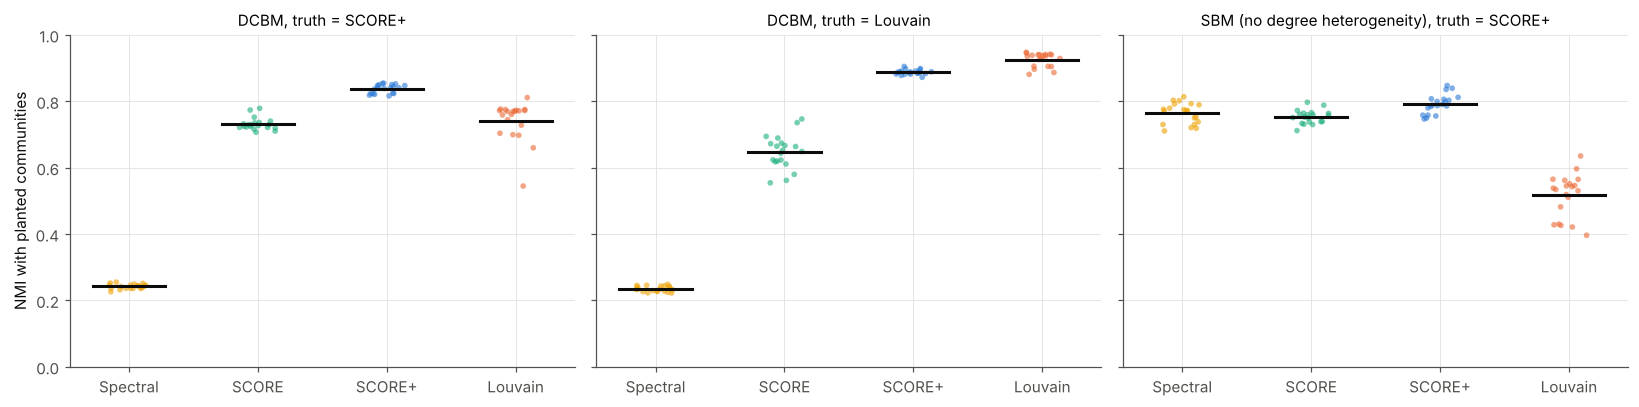

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, (sname, _, _) in zip(axs, settings):
    d_ = sim[sim.setting == sname]
    for j, m in enumerate(METHOD_ORDER):
        y = d_[d_.method == m].NMI.values
        a.scatter(np.full(len(y), j) + np.random.default_rng(j).uniform(-0.15, 0.15, len(y)), y, s=14, color=METHOD_COLOR[m], alpha=0.6, edgecolor='none')
        a.plot([j - 0.28, j + 0.28], [y.mean()] * 2, color=INK, lw=2)
    a.set_xticks(range(4)); a.set_xticklabels(METHOD_ORDER); a.set_title(sname, fontsize=10)
    a.set_ylim(0, 1)
axs[0].set_ylabel('NMI with planted communities')
fig.tight_layout(); savefig(fig, 'figA1_simulation'); plt.show()

> **Interpretation.** The simulation separates *which method is right* from *which method finds more taste sharing*.
- **Under degree heterogeneity (DCBM), spectral clustering on $A$ fails completely** (NMI ≈0.24 in both DCBM settings, ARI ≈0.02). The identical block structure **without** degree heterogeneity (SBM) is recovered well by spectral clustering (NMI 0.77). So the failure on the real data is caused by degree heterogeneity, as the DCBM theory in Lec9 predicts, and not by weak block structure.
- **Plain SCORE helps but is not enough** (NMI 0.65–0.73), consistent with the localization diagnostic in §2.1.
- **SCORE+ is the most reliable across settings**: best when the planted truth is the SCORE+ partition (0.84) and only slightly behind Louvain (0.89 vs. 0.93) when the truth is the *Louvain* partition. It does not just favour structures it produced itself.
- **Louvain** is excellent on its own planted structure but drops to 0.74 on the SCORE+ structure and to 0.52 on the SBM, where it picks a different number of communities.

Overall, SCORE+ is a sensible main method for this network, and spectral clustering on the raw adjacency matrix should not be used here.

## 9. Summary

In [28]:
choices = pd.DataFrame([
    ('Sample', f'LCC of users with music data: n = {n:,}, m = {G.number_of_edges():,}'),
    ('Eigen-decomposition', 'scipy.sparse.linalg.eigsh, top 30 eigenpairs by |eigenvalue|'),
    ('k-means', f'scikit-learn KMeans, {N_INIT} random starts, seed {SEED}'),
    ('Number of communities K', f'K* = {K_STAR}: largest relative eigengap of L_τ in 3..20; checked with community sizes and edge-subsampling stability (no music data used)'),
    ('SCORE truncation', 'ratios truncated at ±log n (Jin 2015)'),
    ('SCORE+ regularization τ', f'τ = d̄ = {deg.mean():.2f} (Lec9 slide 28); published default 0.1·d_max = {0.1*deg.max():.1f} re-introduces localization (tab02), reported as robustness'),
    ('SCORE+ threshold t', 't = 0.1 (Jin, Ke & Luo 2021 default)'),
    ('Louvain', f'networkx.community.louvain_communities defaults; resolution γ = {GAMMA} chosen so K ≈ K* (default γ=1 gives K = {louv_default.max()+1}); seed {SEED}'),
    ('Similarity', 'Jaccard index of liked-artist sets'),
    ('Test statistic', 'T = mean of within-community means − mean of between-community means'),
    ('Permutation strata', '5×5 quantile bins of degree × #artists (main); country (confounder check)'),
    ('# permutations', f'{B_MAIN} (main and country tests), {B_ROBUST} (robustness)'),
    ('Simulation', f'DCBM/SBM with parameters estimated from the real data, {N_SIM} replications per setting'),
], columns=['Choice', 'Value'])
savetab(choices, 'tab13_implementation_choices')
choices

,Choice,Value
0,Sample,"LCC of users with music data: n = 7,431, m = 2..."
1,Eigen-decomposition,"scipy.sparse.linalg.eigsh, top 30 eigenpairs b..."
2,k-means,"scikit-learn KMeans, 20 random starts, seed 236"
3,Number of communities K,K* = 11: largest relative eigengap of L_τ in 3...
4,SCORE truncation,ratios truncated at ±log n (Jin 2015)
5,SCORE+ regularization τ,τ = d̄ = 7.28 (Lec9 slide 28); published defau...
6,SCORE+ threshold t,"t = 0.1 (Jin, Ke & Luo 2021 default)"
7,Louvain,networkx.community.louvain_communities default...
8,Similarity,Jaccard index of liked-artist sets
9,Test statistic,T = mean of within-community means − mean of b...


### Key findings

1. **Yes, a social circle is (partly) a music circle.** Using only the follow network, SCORE+ finds 11 communities. Users in the same community share 36% more artists (Jaccard) than users in different communities. This is far beyond what degree and activity explain ($p\approx0.001$, $z\approx318$).
2. **About half of the effect is country.** Communities are fairly country-aligned. Shuffling music within country reproduces ≈52% of the SCORE+ effect, but the remaining half is still highly significant ($z\approx64$).
3. **The shared taste is niche, not mainstream.** Removing the 10% most popular artists increases the within/between ratio from 1.36 to 1.88.
4. **The method matters for interpretation, not for direction.** All methods give $T>0$. Spectral clustering on $A$ groups users by popularity (one giant cluster plus hub clusters), and its apparent effect reverses under pair weighting. Louvain's communities are mostly country groups. SCORE and SCORE+ correct for degree heterogeneity.
5. **Why SCORE needed SCORE+ here.** The network is very sparse with extreme hubs ($d_{\max}/\bar d=29$), so the leading eigenvectors of $A$ localize on a few hubs and ≈39% of SCORE's ratios are truncated. Regularizing the Laplacian with $\tau=\bar d$ fixes this. A DCBM simulation calibrated to the data confirms the ranking: spectral NMI 0.24, SCORE 0.73, SCORE+ 0.84.

### Three takeaways (for the lightning talk / webpage)

1. **Friends of friends listen alike.** Social communities found from follows alone share ~36% more music taste than random groups, and the effect survives controls for activity and country.
2. **Half of it is geography, half is social.** Country explains about half of the shared taste. The rest is genuine social-circle homophily, concentrated in niche artists.
3. **Degree correction is not optional.** On hub-dominated networks plain spectral clustering clusters by popularity. SCORE+ (regularized Laplacian + SCORE ratios) recovers communities reliably, as confirmed by simulation.

### Limitations

- **Association, not causation.** Static data cannot tell whether shared taste leads to following (selection) or following leads to shared taste (influence).
- **Liked artists ≠ listening history**, and the released artist list seems pre-filtered to artists with ≳100 fans, so very niche taste is not observed. Artist IDs are anonymous, so communities cannot be described by genre.
- **Country is anonymized and coarse.** Other shared factors (city, language, age) could explain part of the remaining effect.
- **The community-averaged $T$ is sensitive to many small clusters** (Spectral). We therefore report the pair-weighted version as well.
- **Choice of $K$ and $\tau$** involves judgment. We report all settings, and the conclusion holds across them.
- The data were obtained from the dataset authors' `karateclub` repository (the SNAP download was not reachable from our environment). It is the same LastFM Asia network (identical node and edge counts), and the loader also accepts the SNAP files.

In [29]:
print('Figures:', sorted(os.listdir(FIG_DIR)))
print('Tables :', sorted(os.listdir(TAB_DIR)))

Figures: ['fig01_degree_artists.png', 'fig02_localization.png', 'fig03_K_selection.png', 'fig04_community_sizes.png', 'fig05_similarity_matrix.png', 'fig06_permutation_nulls.png', 'fig07_method_comparison.png', 'fig08_robustness.png', 'fig09_network.png', 'fig10_community_graph.png', 'figA1_simulation.png']
Tables : ['tab01_data_summary.csv', 'tab02_localization.csv', 'tab03_K_selection.csv', 'tab04_louvain_resolution.csv', 'tab05_community_sizes.csv', 'tab06_main_test.csv', 'tab07_scoreplus_communities.csv', 'tab08_country_check.csv', 'tab09_nmi_matrix.csv', 'tab10_hub_placement.csv', 'tab11_method_comparison.csv', 'tab12_robustness.csv', 'tab13_implementation_choices.csv', 'tabA1_simulation_raw.csv', 'tabA2_simulation_summary.csv']


### References
- Rozemberczki, B. and Sarkar, R. (2020). Characteristic functions on graphs: birds of a feather, from statistical descriptors to parametric models. *CIKM*.
- Jin, J. (2015). Fast community detection by SCORE. *Annals of Statistics* 43(1), 57–89.
- Jin, J., Ke, Z. T. and Luo, S. (2021). Improvements on SCORE, especially for weak signals. *Sankhya A* 84, 127–162.
- Karrer, B. and Newman, M. E. J. (2011). Stochastic blockmodels and community structure in networks. *Physical Review E* 83, 016107.
- Blondel, V. D., Guillaume, J.-L., Lambiotte, R. and Lefebvre, E. (2008). Fast unfolding of communities in large networks. *J. Stat. Mech.* P10008.
- Qin, T. and Rohe, K. (2013). Regularized spectral clustering under the degree-corrected stochastic blockmodel. *NeurIPS*.